# Project Work part 2 - Data Sources


Name: Alina Shah  
GitHub: https://github.com/59762/IND320-59762  
Streamlit: https://ind320-59762.streamlit.app/

In [1]:
import os, sys
os.environ["HADOOP_HOME"] = r"C:\hadoop"
os.environ["hadoop.home.dir"] = r"C:\hadoop"
os.environ["PATH"] += os.pathsep + r"C:\hadoop\bin"
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

**Setup and credentials**

The ENTSO-E token and the MongoDB connection string are read from `.streamlit/secrets.toml` (the same file the Streamlit app uses locally), with environment variables as a fallback. The secrets are never printed, and the file is listed in `.gitignore` so it is not pushed to GitHub.

Run this notebook from the root of the repository, so the relative path to `.streamlit/secrets.toml` works.

In [2]:
import os
import re
import time
import tomllib                     
from datetime import datetime, timedelta, timezone
from pathlib import Path
import xml.etree.ElementTree as ET
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)


def load_secrets(path=".streamlit/secrets.toml"):
    p = Path(path)
    if p.exists():
        with open(p, "rb") as f:
            return tomllib.load(f)
    return {}


SECRETS = load_secrets()
ENTSOE_TOKEN = SECRETS.get("entsoe_token") or os.getenv("ENTSOE_TOKEN")
MONGODB_URI = SECRETS.get("mongodb_uri") or os.getenv("MONGODB_URI")

# Only report whether the secrets were found - never print the values
print("ENTSO-E token found:", bool(ENTSOE_TOKEN))
print("MongoDB URI found:  ", bool(MONGODB_URI))
assert ENTSOE_TOKEN and MONGODB_URI, "Add entsoe_token and mongodb_uri to .streamlit/secrets.toml"

ENTSO-E token found: True
MongoDB URI found:   True


Cassandra runs locally and is used as the raw data store for the API data. If Cassandra is not running yet, it can for example be started with Docker:

`docker run --name cassandra -p 9042:9042 -d cassandra:latest`

In [3]:
import os
os.environ["HADOOP_HOME"] = r"C:\hadoop"
os.environ["hadoop.home.dir"] = r"C:\hadoop"
os.environ["PATH"] += os.pathsep + r"C:\hadoop\bin"

import pyspark
from pyspark.sql import SparkSession, functions as F
from pyspark.sql import types as T

CASSANDRA_HOST = "127.0.0.1"
CASSANDRA_PORT = 9042
KEYSPACE = "ind320"
TABLE = "entsoe_flows"

# Spark Cassandra Connector version must match the Spark version
CONNECTOR_BY_SPARK = {
    "3.3": "com.datastax.spark:spark-cassandra-connector_2.12:3.3.0",
    "3.4": "com.datastax.spark:spark-cassandra-connector_2.12:3.4.1",
    "3.5": "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1",
}
spark_minor = ".".join(pyspark.__version__.split(".")[:2])
CONNECTOR = CONNECTOR_BY_SPARK.get(spark_minor)
if CONNECTOR is None:
    raise RuntimeError(
        f"No connector mapped for Spark {pyspark.__version__}. "
        "Set CONNECTOR manually to a matching spark-cassandra-connector package."
    )

spark = (
    SparkSession.builder
    .appName("IND320-part2")
    .master("local[*]")
    .config("spark.jars.packages", CONNECTOR)
    .config("spark.cassandra.connection.host", CASSANDRA_HOST)
    .config("spark.cassandra.connection.port", str(CASSANDRA_PORT))
    .config("spark.sql.session.timeZone", "UTC")      # keep everything in UTC
    .config("spark.driver.host", "127.0.0.1")
    .config("spark.driver.bindAddress", "127.0.0.1")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")
print("Spark version:", spark.version, "| connector:", CONNECTOR)

Spark version: 3.5.1 | connector: com.datastax.spark:spark-cassandra-connector_2.12:3.5.1


In [4]:
# Connect to Cassandra with the Python driver and create keyspace + table
from cassandra.cluster import Cluster

cluster = Cluster([CASSANDRA_HOST], port=CASSANDRA_PORT)
cass_session = cluster.connect()
print("Cassandra version:", cass_session.execute("SELECT release_version FROM system.local").one()[0])

cass_session.execute(f'''
    CREATE KEYSPACE IF NOT EXISTS {KEYSPACE}
    WITH replication = {{'class': 'SimpleStrategy', 'replication_factor': 1}}
''')

# One partition per connection + direction + year; rows sorted by time inside the partition.
# Re-inserting the same (corridor, direction, year, ts) overwrites the row, so re-running is safe.
cass_session.execute(f'''
    CREATE TABLE IF NOT EXISTS {KEYSPACE}.{TABLE} (
        corridor       text,
        direction      text,
        year           int,
        ts             timestamp,
        flow_mw        double,
        resolution_min int,
        out_zone       text,
        in_zone        text,
        PRIMARY KEY ((corridor, direction, year), ts)
    ) WITH CLUSTERING ORDER BY (ts ASC)
''')
print(f"Keyspace '{KEYSPACE}' and table '{TABLE}' are ready")

Cassandra version: 4.1.12
Keyspace 'ind320' and table 'entsoe_flows' are ready


In [5]:
# Check that Spark can read from Cassandra through the connector
(
    spark.read
    .format("org.apache.spark.sql.cassandra")
    .options(keyspace=KEYSPACE, table=TABLE)
    .load()
    .printSchema()
)
print("Spark-Cassandra connection works")

root
 |-- connection: string (nullable = false)
 |-- timestamp: timestamp (nullable = true)
 |-- direction: string (nullable = true)
 |-- value_mwh: double (nullable = true)

Spark-Cassandra connection works


In [6]:
from pymongo import MongoClient

mongo_client = MongoClient(MONGODB_URI, serverSelectionTimeoutMS=15000)
mongo_client.admin.command("ping")                 # raises an error if the connection fails
mongo_db = mongo_client["ind320"]
print("Connected to MongoDB. Databases visible:", mongo_client.list_database_names())

# CRUD test on a temporary collection
test_col = mongo_db["_connection_test"]
test_col.delete_many({})
test_col.insert_one({"name": "test", "value": 1})                                   # Create
print("Read:   ", test_col.find_one({"name": "test"}, {"_id": 0}))                   # Read
test_col.update_one({"name": "test"}, {"$set": {"value": 2}})                       # Update
print("Updated:", test_col.find_one({"name": "test"}, {"_id": 0}))
test_col.delete_many({})                                                            # Delete
print("Documents left after delete:", test_col.count_documents({}))

Connected to MongoDB. Databases visible: ['ind320', 'admin', 'local']
Read:    {'name': 'test', 'value': 1}
Updated: {'name': 'test', 'value': 2}
Documents left after delete: 0


The reservoir data is now fetched directly from the NVE API instead of `data/reservoirs.csv`.

In [7]:
NVE_BASE = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk"

# Download all public reservoir statistics
resp = requests.get(f"{NVE_BASE}/HentOffentligData", timeout=60)
resp.raise_for_status()
nve_raw = pd.DataFrame(resp.json())
print("Rows downloaded:", len(nve_raw))
print("Original (Norwegian) columns:", nve_raw.columns.tolist())

# Rename to the same English names as in part 1
nve_all = nve_raw.rename(columns={
    "dato_Id":                  "date",
    "omrType":                  "area_type",
    "omrnr":                    "area_nr",
    "iso_aar":                  "year",
    "iso_uke":                  "week",
    "fyllingsgrad":             "fill_level",
    "kapasitet_TWh":            "capacity_TWh",
    "fylling_TWh":              "stored_energy_TWh",
    "neste_Publiseringsdato":   "next_publish_date",
    "fyllingsgrad_forrige_uke": "fill_level_previous_week",
    "endring_fyllingsgrad":     "change_in_fill_level",
})

# Convert the text dates to datetime and sort chronologically
nve_all["date"] = pd.to_datetime(nve_all["date"], errors="coerce")
if "next_publish_date" in nve_all.columns:
    nve_all["next_publish_date"] = pd.to_datetime(nve_all["next_publish_date"], errors="coerce")
nve_all = nve_all.sort_values(["area_type", "area_nr", "date"]).reset_index(drop=True)

nve_all.info()
nve_all.head()

Rows downloaded: 14931
Original (Norwegian) columns: ['dato_Id', 'omrType', 'omrnr', 'iso_aar', 'iso_uke', 'fyllingsgrad', 'kapasitet_TWh', 'fylling_TWh', 'neste_Publiseringsdato', 'fyllingsgrad_forrige_uke', 'endring_fyllingsgrad']
<class 'pandas.DataFrame'>
RangeIndex: 14931 entries, 0 to 14930
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   date                      14931 non-null  datetime64[us]
 1   area_type                 14931 non-null  str           
 2   area_nr                   14931 non-null  int64         
 3   year                      14931 non-null  int64         
 4   week                      14931 non-null  int64         
 5   fill_level                14931 non-null  float64       
 6   capacity_TWh              14931 non-null  float64       
 7   stored_energy_TWh         14931 non-null  float64       
 8   next_publish_date         14931 non-null  da

,date,area_type,area_nr,year,week,fill_level,capacity_TWh,stored_energy_TWh,next_publish_date,fill_level_previous_week,change_in_fill_level
0,1995-01-08,EL,1,1995,1,0.617574,6.003264,3.707457,0001-01-01,0.583705,0.033869
1,1995-01-15,EL,1,1995,2,0.579205,6.003264,3.477117,0001-01-01,0.617574,-0.038369
2,1995-01-22,EL,1,1995,3,0.546713,6.003264,3.282063,0001-01-01,0.579205,-0.032491
3,1995-01-29,EL,1,1995,4,0.504545,6.003264,3.028916,0001-01-01,0.546713,-0.042168
4,1995-02-05,EL,1,1995,5,0.465335,6.003264,2.793528,0001-01-01,0.504545,-0.039210


In [8]:
# One row per area: how many weekly observations and which period it covers
areas = (
    nve_all.groupby(["area_type", "area_nr"])
    .agg(first_date=("date", "min"), last_date=("date", "max"), n_weeks=("date", "count"))
    .reset_index()
)

# Summary per area type
area_summary = (
    areas.groupby("area_type")
    .agg(
        n_areas=("area_nr", "nunique"),
        area_numbers=("area_nr", lambda s: sorted(s.tolist())),
        first_date=("first_date", "min"),
        last_date=("last_date", "max"),
    )
)
display(area_summary)

print("Full list of areas:")
display(areas)

,n_areas,area_numbers,first_date,last_date
area_type,,,,
EL,5,"[1, 2, 3, 4, 5]",1995-01-08,2026-10-18
NO,1,[0],1995-01-08,2026-10-18
VASS,3,"[1, 2, 3]",1995-01-08,2026-10-18


Full list of areas:


,area_type,area_nr,first_date,last_date,n_weeks
0,EL,1,1995-01-08,2026-10-18,1659
1,EL,2,1995-01-08,2026-10-18,1659
2,EL,3,1995-01-08,2026-10-18,1659
3,EL,4,1995-01-08,2026-10-18,1659
4,EL,5,1995-01-08,2026-10-18,1659
5,NO,0,1995-01-08,2026-10-18,1659
6,VASS,1,1995-01-08,2026-10-18,1659
7,VASS,2,1995-01-08,2026-10-18,1659
8,VASS,3,1995-01-08,2026-10-18,1659


In [9]:
# Select one area from the API data
AREA_TYPE = "NO"                       # one of EL, NO, VASS
AREA_NR = None                         # None = first area number of the chosen type

subset = nve_all[nve_all["area_type"] == AREA_TYPE]
assert len(subset) > 0, f"No data for area type {AREA_TYPE}"
if AREA_NR is None:
    AREA_NR = sorted(subset["area_nr"].unique())[0]

df = subset[subset["area_nr"] == AREA_NR].sort_values("date").reset_index(drop=True)
print(f"Area type {AREA_TYPE}, area number {AREA_NR}: {len(df)} weekly rows, "
      f"{df['date'].min().date()} to {df['date'].max().date()}")

# Numerical reservoir columns (same as part 1)
plot_columns = [
    "fill_level",
    "capacity_TWh",
    "stored_energy_TWh",
    "fill_level_previous_week",
    "change_in_fill_level",
]

display(df[plot_columns].describe().T)

Area type NO, area number 0: 1659 weekly rows, 1995-01-08 to 2026-10-18


,count,mean,std,min,25%,50%,75%,max
fill_level,1659.0,0.622211,0.195640,0.180250,0.461269,0.647641,0.788371,0.966610
capacity_TWh,1659.0,87.437580,0.000000,87.437580,87.437580,87.437580,87.437580,87.437580
stored_energy_TWh,1659.0,54.404637,17.106297,15.760602,40.332257,56.628166,68.933230,84.518060
fill_level_previous_week,1659.0,0.622247,0.195658,0.180260,0.461269,0.647689,0.788369,0.966610
change_in_fill_level,1659.0,-0.000036,0.027665,-0.144643,-0.022016,-0.005505,0.016266,0.125774


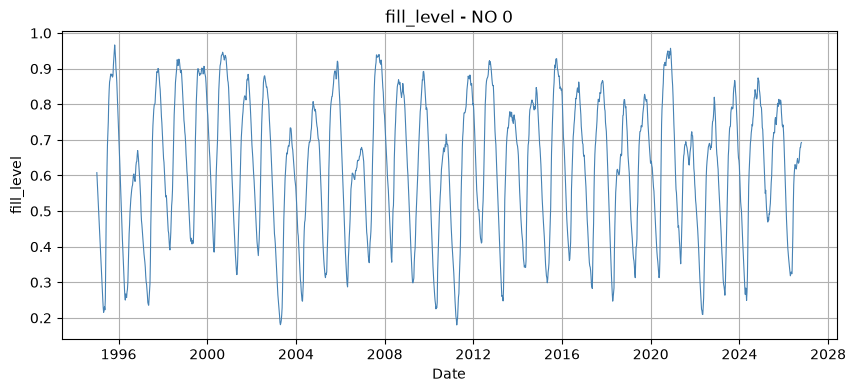

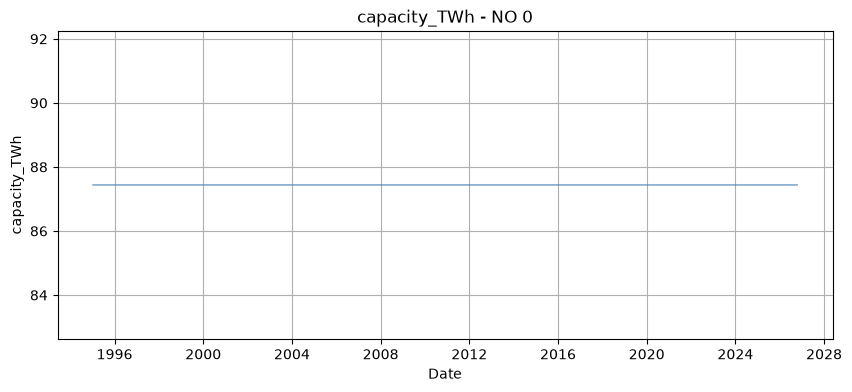

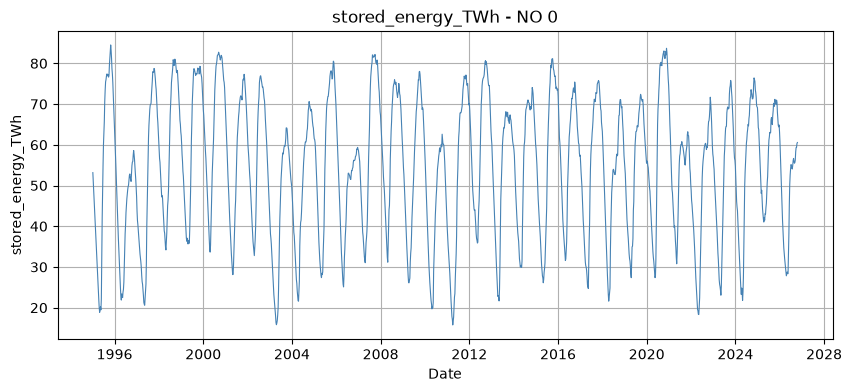

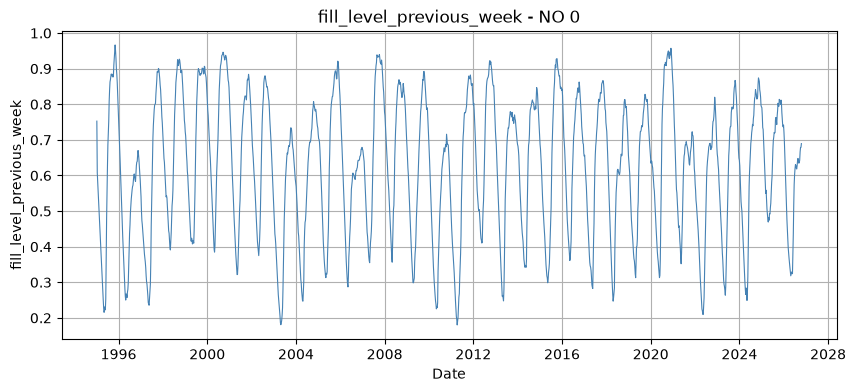

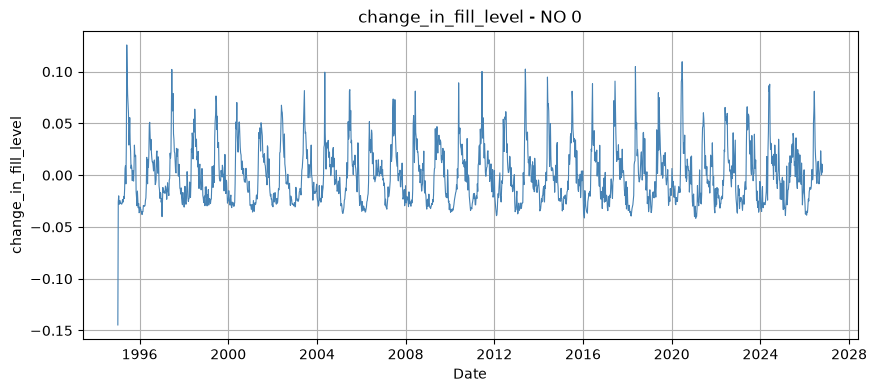

In [10]:
# Plot each numerical column separately
for column in plot_columns:
    plt.figure(figsize=(10, 4))
    plt.plot(df["date"], df[column], linewidth=0.8, color="steelblue")
    plt.title(f"{column} - {AREA_TYPE} {AREA_NR}")
    plt.xlabel("Date")
    plt.ylabel(column)
    plt.grid(True)
    plt.show()

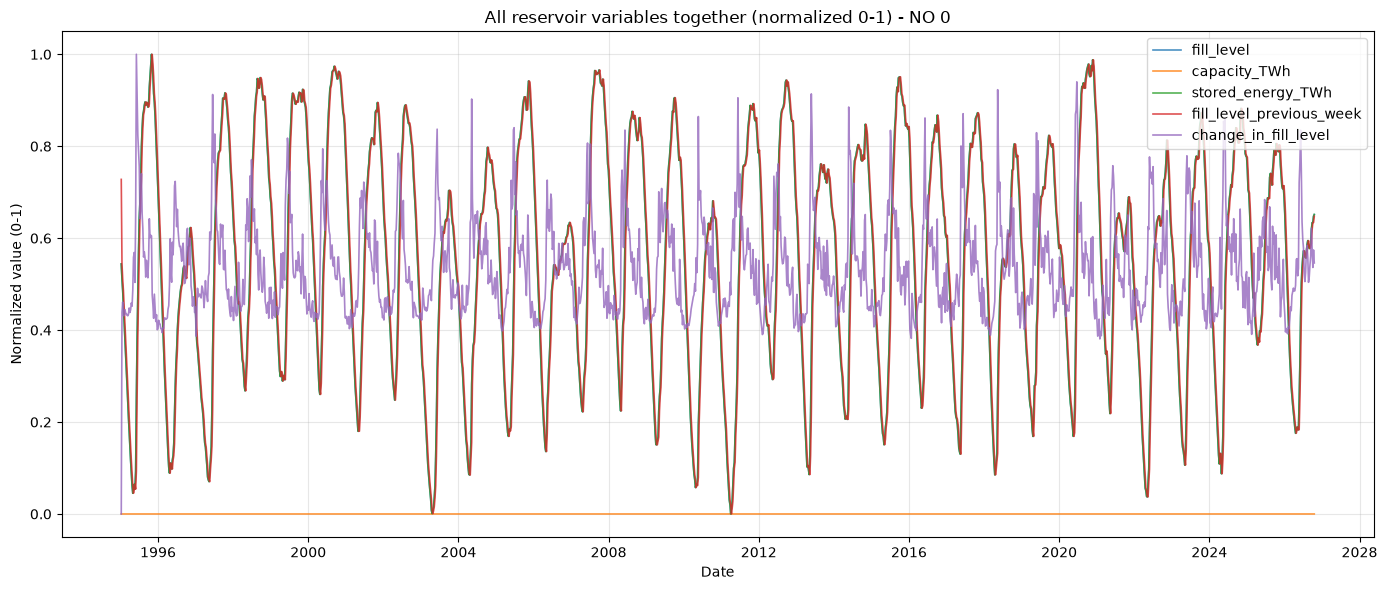

In [12]:
# Plot all variables together, min-max normalised to 0-1 so the different units are comparable
df_norm = df.copy()
for col in plot_columns:
    mn, mx = df[col].min(), df[col].max()
    # Guard against division by zero if a column is constant
    df_norm[col] = (df[col] - mn) / (mx - mn) if mx != mn else 0.0

plt.figure(figsize=(14, 6))
for col in plot_columns:
    plt.plot(df["date"], df_norm[col], linewidth=1.2, alpha=0.8, label=col)

plt.title(f"All reservoir variables together (normalized 0-1) - {AREA_TYPE} {AREA_NR}")
plt.xlabel("Date")
plt.ylabel("Normalized value (0-1)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### NVE reservoir data: Spark to Cassandra

The reservoir data from the NVE API is loaded into a Spark DataFrame and written to its own Cassandra table, the same way as the ENTSO-E flows. The columns needed later are then extracted from Cassandra with Spark.

In [13]:
NVE_TABLE = "nve_reservoirs"

# One partition per area (type + number), rows sorted by date. Re-running overwrites the same rows.
cass_session.execute(f'''
    CREATE TABLE IF NOT EXISTS {KEYSPACE}.{NVE_TABLE} (
        area_type         text,
        area_nr           int,
        date              date,
        year              int,
        week              int,
        fill_level        double,
        capacity_twh      double,
        stored_energy_twh double,
        PRIMARY KEY ((area_type, area_nr), date)
    ) WITH CLUSTERING ORDER BY (date ASC)
''')

nve_schema = T.StructType([
    T.StructField("area_type",         T.StringType(),  False),
    T.StructField("area_nr",           T.IntegerType(), False),
    T.StructField("date",              T.DateType(),    False),
    T.StructField("year",              T.IntegerType(), True),
    T.StructField("week",              T.IntegerType(), True),
    T.StructField("fill_level",        T.DoubleType(),  True),
    T.StructField("capacity_twh",      T.DoubleType(),  True),
    T.StructField("stored_energy_twh", T.DoubleType(),  True),
])

def num(v):
    # NaN -> None so Spark/Cassandra store a null instead of NaN
    return None if pd.isna(v) else float(v)

# Rows without a key (date, area) cannot be stored in Cassandra, so they are dropped
nve_clean = nve_all.dropna(subset=["date", "area_type", "area_nr"])
print("Rows dropped because of missing key values:", len(nve_all) - len(nve_clean))

nve_rows = [
    (str(t), int(n), d.date(),
     None if pd.isna(y) else int(y), None if pd.isna(w) else int(w),
     num(f), num(c), num(s))
    for t, n, d, y, w, f, c, s in zip(
        nve_clean["area_type"], nve_clean["area_nr"], nve_clean["date"],
        nve_clean["year"], nve_clean["week"], nve_clean["fill_level"],
        nve_clean["capacity_TWh"], nve_clean["stored_energy_TWh"])
]
sdf_nve = spark.createDataFrame(nve_rows, schema=nve_schema)
print("Spark DataFrame rows to insert:", sdf_nve.count())

(
    sdf_nve.write
    .format("org.apache.spark.sql.cassandra")
    .mode("append")
    .options(keyspace=KEYSPACE, table=NVE_TABLE)
    .save()
)
print("NVE write to Cassandra finished")

Rows dropped because of missing key values: 0
Spark DataFrame rows to insert: 14931
NVE write to Cassandra finished


In [14]:
# Read back from Cassandra with Spark and keep only the relevant columns
nve_cass = (
    spark.read.format("org.apache.spark.sql.cassandra")
    .options(keyspace=KEYSPACE, table=NVE_TABLE)
    .load()
)
nve_sdf = (
    nve_cass
    .select("area_type", "area_nr", "date", "year", "week", "fill_level", "capacity_twh", "stored_energy_twh")
    .orderBy("area_type", "area_nr", "date")
)

n_cass, n_sent = nve_sdf.count(), len(nve_rows)
print(f"Rows in Cassandra: {n_cass} | rows sent: {n_sent}")
assert n_cass >= n_sent, "Fewer rows in Cassandra than were written"

nve_spark_pd = pd.DataFrame([r.asDict() for r in nve_sdf.collect()])
nve_spark_pd["date"] = pd.to_datetime(nve_spark_pd["date"])
nve_spark_pd.head()

Rows in Cassandra: 14931 | rows sent: 14931


,area_type,area_nr,date,year,week,fill_level,capacity_twh,stored_energy_twh
0,EL,1,1995-01-08,1995,1,0.617574,6.003264,3.707457
1,EL,1,1995-01-15,1995,2,0.579205,6.003264,3.477117
2,EL,1,1995-01-22,1995,3,0.546713,6.003264,3.282063
3,EL,1,1995-01-29,1995,4,0.504545,6.003264,3.028916
4,EL,1,1995-02-05,1995,5,0.465335,6.003264,2.793528


Physical cross-border flows are retrieved from the [ENTSO-E Transparency Platform](https://transparency.entsoe.eu/) using document type `A11`.

In [15]:
# Bidding zones: code -> (EIC code, country)
ZONES = {
    "NO1":   ("10YNO-1--------2",   "Norway"),
    "NO2":   ("10YNO-2--------T",   "Norway"),
    "NO3":   ("10YNO-3--------J",   "Norway"),
    "NO4":   ("10YNO-4--------9",   "Norway"),
    "SE1":   ("10Y1001A1001A44P",   "Sweden"),
    "SE2":   ("10Y1001A1001A45N",   "Sweden"),
    "SE3":   ("10Y1001A1001A46L",   "Sweden"),
    "FI":    ("10YFI-1--------U",   "Finland"),
    "DK1":   ("10YDK-1--------W",   "Denmark"),
    "DE-LU": ("10Y1001A1001A82H",   "Germany"),
    "GB":    ("10YGB----------A",   "Great Britain"),
    "NL":    ("10YNL----------L",   "Netherlands"),
}

# Norwegian zone first, foreign zone second (same list as the Streamlit app)
CORRIDORS = [
    "NO1 - SE3", "NO2 - DE-LU", "NO2 - DK1", "NO2 - GB", "NO2 - NL",
    "NO3 - SE2", "NO4 - FI", "NO4 - SE1", "NO4 - SE2",
]

# The last two complete calendar years (today is in 2026)
YEARS = [2024, 2025]

ENTSOE_API = "https://web-api.tp.entsoe.eu/api"


def corridor_title(corridor):
    # 'NO2 - DK1' -> 'Norway - Denmark'
    no_zone, foreign_zone = [z.strip() for z in corridor.split(" - ")]
    return f"{ZONES[no_zone][1]} - {ZONES[foreign_zone][1]}"

In [16]:
def resolution_to_minutes(res):
    # ISO 8601 duration used by ENTSO-E, e.g. PT15M, PT30M, PT60M, PT1H
    m = re.fullmatch(r"PT(\d+)([MH])", res.strip())
    if not m:
        raise ValueError(f"Unknown resolution: {res}")
    n, unit = int(m.group(1)), m.group(2)
    return n * 60 if unit == "H" else n


def parse_entsoe_xml(xml_text):
    # Parse an ENTSO-E physical flow XML document into a DataFrame
    # Columns: ts (UTC, timezone-naive), flow_mw, resolution_min.
    # An empty DataFrame is returned for 'no data' (acknowledgement) documents.
    cols = ["ts", "flow_mw", "resolution_min"]
    root = ET.fromstring(xml_text)
    ns = root.tag[1:root.tag.index("}")] if root.tag.startswith("{") else ""
    q = (lambda name: f"{{{ns}}}{name}") if ns else (lambda name: name)

    rows = []
    for series in root.iter(q("TimeSeries")):
        curve_type = series.findtext(q("curveType"))          # A01 = every point, A03 = only changes
        for period in series.findall(q("Period")):
            ti = period.find(q("timeInterval"))
            start = datetime.fromisoformat(ti.findtext(q("start")).replace("Z", "+00:00"))
            end = datetime.fromisoformat(ti.findtext(q("end")).replace("Z", "+00:00"))
            res = resolution_to_minutes(period.findtext(q("resolution")))
            step = timedelta(minutes=res)
            n_slots = int((end - start) / step)

            # position -> quantity as given in the XML
            values = {
                int(pt.findtext(q("position"))): float(pt.findtext(q("quantity")))
                for pt in period.findall(q("Point"))
            }

            last = None
            for pos in range(1, n_slots + 1):
                if pos in values:
                    last = values[pos]
                elif curve_type != "A03":
                    continue                                   # a real gap: leave it missing
                if last is None:
                    continue
                rows.append((start + (pos - 1) * step, last, res))

    if not rows:
        return pd.DataFrame(columns=cols)
    out = pd.DataFrame(rows, columns=cols)
    out["ts"] = pd.to_datetime(out["ts"]).dt.tz_convert("UTC").dt.tz_localize(None)   # naive UTC
    return out.drop_duplicates("ts").sort_values("ts").reset_index(drop=True)


def fetch_flow(out_eic, in_eic, year, retries=3):
    # Download one direction of one connection for one calendar year (UTC)
    params = {
        "securityToken": ENTSOE_TOKEN,
        "documentType":  "A11",
        "out_Domain":    out_eic,
        "in_Domain":     in_eic,
        "periodStart":   f"{year}01010000",
        "periodEnd":     f"{year + 1}01010000",
    }
    for attempt in range(1, retries + 1):
        try:
            r = requests.get(ENTSOE_API, params=params, timeout=90)
        except requests.RequestException as exc:
            if attempt == retries:
                return pd.DataFrame(), f"request failed: {exc}"
            time.sleep(2 * attempt)
            continue
        if r.status_code == 401:
            raise RuntimeError("ENTSO-E rejected the security token (HTTP 401)")
        if r.status_code in (429, 500, 502, 503, 504) and attempt < retries:
            time.sleep(3 * attempt)                            # back off and retry
            continue
        if r.status_code != 200:
            return pd.DataFrame(), f"HTTP {r.status_code}"
        df = parse_entsoe_xml(r.text)
        return df, ("ok" if len(df) else "no data returned")
    return pd.DataFrame(), "failed"

In [17]:
# Download every connection, both directions, for both years
frames, status_rows = [], []

for corridor in CORRIDORS:
    no_zone, foreign_zone = [z.strip() for z in corridor.split(" - ")]
    no_eic, foreign_eic = ZONES[no_zone][0], ZONES[foreign_zone][0]

    directions = {
        "Into Norway":   (foreign_eic, no_eic, foreign_zone, no_zone),
        "Out of Norway": (no_eic, foreign_eic, no_zone, foreign_zone),
    }
    for direction, (out_eic, in_eic, out_zone, in_zone) in directions.items():
        for year in YEARS:
            df_flow, status = fetch_flow(out_eic, in_eic, year)
            status_rows.append({"corridor": corridor, "direction": direction, "year": year,
                                "rows": len(df_flow), "status": status})
            if len(df_flow):
                df_flow = df_flow.assign(corridor=corridor, direction=direction,
                                         out_zone=out_zone, in_zone=in_zone)
                frames.append(df_flow)
            time.sleep(0.3)                                    # be polite to the API

download_status = pd.DataFrame(status_rows)
display(download_status)

flows = pd.concat(frames, ignore_index=True)
flows["year"] = flows["ts"].dt.year.astype(int)               # UTC year, also used as partition key
print("Total rows downloaded:", len(flows))
flows.head()

,corridor,direction,year,rows,status
0,NO1 - SE3,Into Norway,2024,8784,ok
1,NO1 - SE3,Into Norway,2025,15528,ok
2,NO1 - SE3,Out of Norway,2024,8784,ok
3,NO1 - SE3,Out of Norway,2025,15528,ok
4,NO2 - DE-LU,Into Norway,2024,35136,ok
5,NO2 - DE-LU,Into Norway,2025,35040,ok
6,NO2 - DE-LU,Out of Norway,2024,35136,ok
7,NO2 - DE-LU,Out of Norway,2025,35040,ok
8,NO2 - DK1,Into Norway,2024,8784,ok
9,NO2 - DK1,Into Norway,2025,28056,ok


Total rows downloaded: 788976


,ts,flow_mw,resolution_min,corridor,direction,out_zone,in_zone,year
0,2024-01-01 00:00:00,1822.15,60,NO1 - SE3,Into Norway,SE3,NO1,2024
1,2024-01-01 01:00:00,1775.05,60,NO1 - SE3,Into Norway,SE3,NO1,2024
2,2024-01-01 02:00:00,1601.27,60,NO1 - SE3,Into Norway,SE3,NO1,2024
3,2024-01-01 03:00:00,1533.96,60,NO1 - SE3,Into Norway,SE3,NO1,2024
4,2024-01-01 04:00:00,1322.37,60,NO1 - SE3,Into Norway,SE3,NO1,2024


In [18]:
# Quick quality check: resolution used and period covered per connection and direction
quality = (
    flows.groupby(["corridor", "direction"])
    .agg(rows=("ts", "count"), first_ts=("ts", "min"), last_ts=("ts", "max"),
         resolutions_min=("resolution_min", lambda s: sorted(s.unique().tolist())),
         missing_flow=("flow_mw", lambda s: int(s.isna().sum())))
    .reset_index()
)
display(quality)

,corridor,direction,rows,first_ts,last_ts,resolutions_min,missing_flow
0,NO1 - SE3,Into Norway,24312,2024-01-01,2025-12-31 23:45:00,"[15, 60]",0
1,NO1 - SE3,Out of Norway,24312,2024-01-01,2025-12-31 23:45:00,"[15, 60]",0
2,NO2 - DE-LU,Into Norway,70176,2024-01-01,2025-12-31 23:45:00,[15],0
3,NO2 - DE-LU,Out of Norway,70176,2024-01-01,2025-12-31 23:45:00,[15],0
4,NO2 - DK1,Into Norway,36840,2024-01-01,2025-12-31 23:45:00,"[15, 60]",0
5,NO2 - DK1,Out of Norway,36840,2024-01-01,2025-12-31 23:45:00,"[15, 60]",0
6,NO2 - GB,Into Norway,63408,2024-01-01,2025-12-31 23:45:00,"[15, 60]",0
7,NO2 - GB,Out of Norway,63408,2024-01-01,2025-12-31 23:45:00,"[15, 60]",0
8,NO2 - NL,Into Norway,63408,2024-01-01,2025-12-31 23:45:00,"[15, 60]",0
9,NO2 - NL,Out of Norway,63408,2024-01-01,2025-12-31 23:45:00,"[15, 60]",0


In [20]:
from datetime import timezone

# 1) Remove the old table and create it with the right columns
cass_session.execute(f"DROP TABLE IF EXISTS {KEYSPACE}.{TABLE}")
cass_session.execute(f"""
    CREATE TABLE {KEYSPACE}.{TABLE} (
        corridor        text,
        direction       text,
        year            int,
        ts              timestamp,
        flow_mw         double,
        resolution_min  int,
        out_zone        text,
        in_zone         text,
        PRIMARY KEY ((corridor, direction, year), ts)
    )
""")

# 2) Your code, unchanged
cass_schema = T.StructType([
    T.StructField("corridor",       T.StringType(),    False),
    T.StructField("direction",      T.StringType(),    False),
    T.StructField("year",           T.IntegerType(),   False),
    T.StructField("ts",             T.TimestampType(), False),
    T.StructField("flow_mw",        T.DoubleType(),    True),
    T.StructField("resolution_min", T.IntegerType(),   True),
    T.StructField("out_zone",       T.StringType(),    True),
    T.StructField("in_zone",        T.StringType(),    True),
])

rows = [
    (c, d, int(y), t.to_pydatetime().replace(tzinfo=timezone.utc), float(v), int(r), o, i)
    for c, d, y, t, v, r, o, i in zip(
        flows["corridor"], flows["direction"], flows["year"], flows["ts"],
        flows["flow_mw"], flows["resolution_min"], flows["out_zone"], flows["in_zone"])
]
sdf_flows = spark.createDataFrame(rows, schema=cass_schema)
print("Spark DataFrame rows to insert:", sdf_flows.count())

(
    sdf_flows.write
    .format("org.apache.spark.sql.cassandra")
    .mode("append")
    .options(keyspace=KEYSPACE, table=TABLE)
    .save()
)
print("Write to Cassandra finished")

Spark DataFrame rows to insert: 788976
Write to Cassandra finished


In [21]:
# Verify: count the rows that now exist in Cassandra
cass_df = (
    spark.read.format("org.apache.spark.sql.cassandra")
    .options(keyspace=KEYSPACE, table=TABLE)
    .load()
)
print("Rows in Cassandra:", cass_df.count())

Rows in Cassandra: 788976


In [22]:
# Keep only the columns needed and add the energy of each interval (MW x hours = MWh)
base = (
    cass_df
    .select("corridor", "direction", "year", "ts", "flow_mw", "resolution_min")
    .where(F.col("flow_mw").isNotNull())
    .withColumn("energy_mwh", F.col("flow_mw") * F.col("resolution_min") / 60.0)
)

# 1) Yearly totals per connection and direction
yearly_sdf = (
    base.groupBy("corridor", "direction", "year")
    .agg(
        (F.sum("energy_mwh") / 1e6).alias("energy_twh"),
        F.avg("flow_mw").alias("avg_mw"),
        F.max("flow_mw").alias("max_mw"),
        F.count("*").alias("n_obs"),
    )
    .orderBy("corridor", "direction", "year")
)

# 2) Hourly series per connection and direction
hourly_sdf = (
    base.withColumn("hour", F.date_trunc("hour", F.col("ts")))
    .groupBy("corridor", "direction", "year", "hour")
    .agg(F.avg("flow_mw").alias("flow_mw"))
    .withColumn("month", F.month("hour"))
    .withColumn("ts", F.date_format("hour", "yyyy-MM-dd HH:mm:ss"))   # text in UTC (session time zone)
    .select("corridor", "direction", "year", "month", "ts", "flow_mw")
    .orderBy("corridor", "direction", "ts")
)

yearly_sdf.show(40, truncate=False)

+-----------+-------------+----+--------------------+------------------+-----------+-----+
|corridor   |direction    |year|energy_twh          |avg_mw            |max_mw     |n_obs|
+-----------+-------------+----+--------------------+------------------+-----------+-----+
|NO1 - SE3  |Into Norway  |2024|5.389454714999992   |613.5535877732232 |2299.5675  |8784 |
|NO1 - SE3  |Into Norway  |2025|6.139871869627002   |777.5356382668746 |2282.81    |15528|
|NO1 - SE3  |Out of Norway|2024|1.5050296900000002  |171.3376240892532 |2220.6     |8784 |
|NO1 - SE3  |Out of Norway|2025|1.6238328332265075  |180.69018243856246|2156.133545|15528|
|NO2 - DE-LU|Into Norway  |2024|1.2184969750000028  |138.71777948542837|1403.34    |35136|
|NO2 - DE-LU|Into Norway  |2025|0.7667145682499993  |87.52449409246567 |1410.86    |35040|
|NO2 - DE-LU|Out of Norway|2024|6.998108169999859   |796.6880885701115 |1407.36    |35136|
|NO2 - DE-LU|Out of Norway|2025|7.787854610000132   |889.0244988584625 |1406.56    |35040|

In [23]:
# Collect the (small) Spark results into pandas for plotting and for MongoDB
yearly_pd = pd.DataFrame([r.asDict() for r in yearly_sdf.collect()])
hourly_pd = pd.DataFrame([r.asDict() for r in hourly_sdf.collect()])
hourly_pd["ts"] = pd.to_datetime(hourly_pd["ts"])            # naive UTC timestamps

print("Yearly rows:", len(yearly_pd), "| Hourly rows:", len(hourly_pd))
hourly_pd.head()

Yearly rows: 36 | Hourly rows: 315792


,corridor,direction,year,month,ts,flow_mw
0,NO1 - SE3,Into Norway,2024,1,2024-01-01 00:00:00,1822.15
1,NO1 - SE3,Into Norway,2024,1,2024-01-01 01:00:00,1775.05
2,NO1 - SE3,Into Norway,2024,1,2024-01-01 02:00:00,1601.27
3,NO1 - SE3,Into Norway,2024,1,2024-01-01 03:00:00,1533.96
4,NO1 - SE3,Into Norway,2024,1,2024-01-01 04:00:00,1322.37


In [24]:
# Choices used by the pie chart and the line plots below
CHOSEN_CORRIDOR = "NO2 - DK1"          # any entry of CORRIDORS
CHOSEN_YEAR = 2025                     # one of YEARS

PIE_COLORS  = {"Into Norway": "#0072B2", "Out of Norway": "#D55E00"}     # same colours as the Streamlit app
LINE_COLORS = {"Into Norway": "#1f77b4", "Out of Norway": "#ff7f0e"}

assert CHOSEN_CORRIDOR in CORRIDORS, f"Unknown connection: {CHOSEN_CORRIDOR}"
assert CHOSEN_YEAR in YEARS, f"Year must be one of {YEARS}"
assert ((yearly_pd["corridor"] == CHOSEN_CORRIDOR) & (yearly_pd["year"] == CHOSEN_YEAR)).any(), \
    "No data for this connection/year - choose another one (see the download status table above)"
print(f"Selected: {CHOSEN_CORRIDOR} ({corridor_title(CHOSEN_CORRIDOR)}), {CHOSEN_YEAR}")

Selected: NO2 - DK1 (Norway - Denmark), 2025


### Pie chart: total yearly transfer for one connection

Each piece of the pie is the amount of energy that flowed *into* or *out of* Norway through the chosen connection during the chosen year.

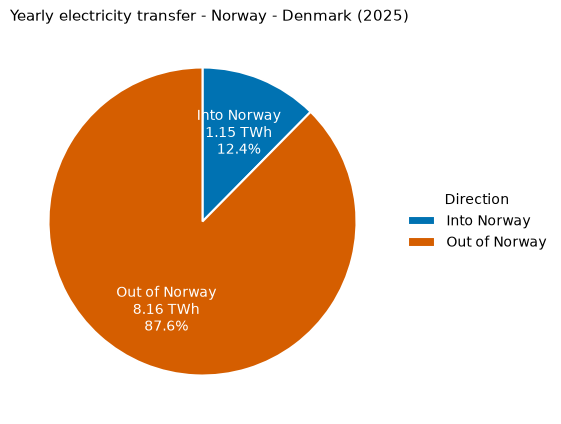

In [25]:
# Yearly energy per direction for the chosen connection and year (from the Spark extract)
sel = yearly_pd[(yearly_pd["corridor"] == CHOSEN_CORRIDOR) & (yearly_pd["year"] == CHOSEN_YEAR)]
totals = sel.set_index("direction")["energy_twh"]
labels = [d for d in ["Into Norway", "Out of Norway"] if d in totals.index]
values = [totals[d] for d in labels]

if sum(values) == 0 or not values:
    print("No data for this connection/year")
else:
    fig, ax = plt.subplots(figsize=(7, 5))
    wedges, texts, autotexts = ax.pie(
        values,
        colors=[PIE_COLORS[d] for d in labels],
        autopct=lambda p: "",                 # labels are written below with TWh and %
        startangle=90, counterclock=False, pctdistance=0.62,
        wedgeprops={"edgecolor": "white", "linewidth": 1.5},
        textprops={"color": "white", "fontsize": 10, "ha": "center"},
    )
    for at, lab, val in zip(autotexts, labels, values):
        at.set_text(f"{lab}\n{val:.2f} TWh\n{val / sum(values) * 100:.1f}%")
    ax.legend(wedges, labels, title="Direction", loc="center left",
              bbox_to_anchor=(1.0, 0.5), frameon=False)
    ax.set_title(f"Yearly electricity transfer - {corridor_title(CHOSEN_CORRIDOR)} ({CHOSEN_YEAR})",
                 loc="left", fontsize=11)
    plt.show()

### Line plot: first month of the year

January of the chosen year. The first plot shows the chosen connection (one line per direction). The second plot shows **all connections**, with one line for each connection *and* direction (colour = connection, solid line = into Norway, dashed line = out of Norway).

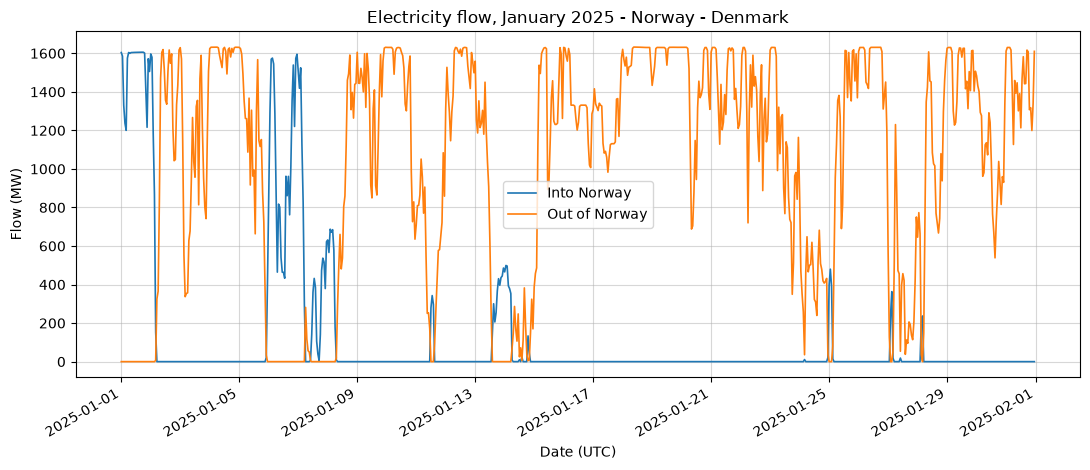

In [26]:
# Line plot 1: the chosen connection, January, one line per direction
jan = hourly_pd[(hourly_pd["year"] == CHOSEN_YEAR) & (hourly_pd["month"] == 1)]
one = jan[jan["corridor"] == CHOSEN_CORRIDOR]

fig, ax = plt.subplots(figsize=(11, 4.8))
for direction in ["Into Norway", "Out of Norway"]:
    d = one[one["direction"] == direction].sort_values("ts")
    if len(d):
        ax.plot(d["ts"], d["flow_mw"], color=LINE_COLORS[direction], linewidth=1.2, label=direction)

ax.set_title(f"Electricity flow, January {CHOSEN_YEAR} - {corridor_title(CHOSEN_CORRIDOR)}")
ax.set_xlabel("Date (UTC)")
ax.set_ylabel("Flow (MW)")
ax.grid(True, alpha=0.5)
ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

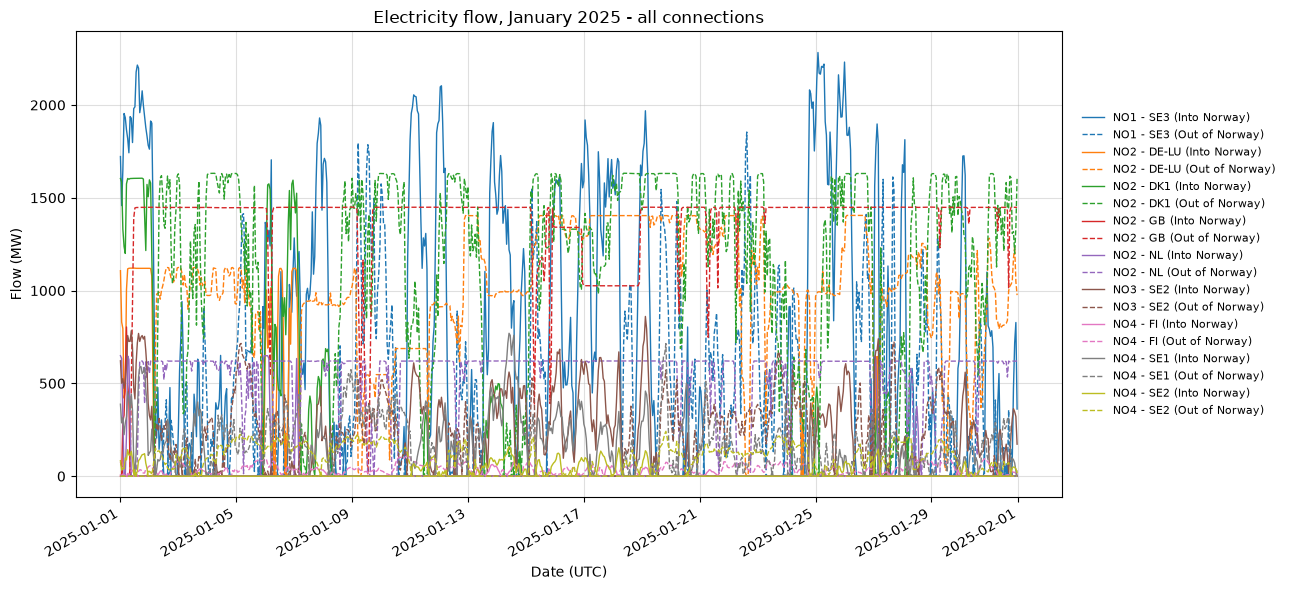

In [27]:
# Line plot 2: all connections, January, separate line for each connection and direction
fig, ax = plt.subplots(figsize=(13, 6))
palette = plt.cm.tab10(np.linspace(0, 1, 10))
corridor_color = {c: palette[i % 10] for i, c in enumerate(CORRIDORS)}

for corridor in CORRIDORS:
    for direction, linestyle in [("Into Norway", "-"), ("Out of Norway", "--")]:
        d = jan[(jan["corridor"] == corridor) & (jan["direction"] == direction)].sort_values("ts")
        if len(d):
            ax.plot(d["ts"], d["flow_mw"], color=corridor_color[corridor],
                    linestyle=linestyle, linewidth=1.0, label=f"{corridor} ({direction})")

ax.set_title(f"Electricity flow, January {CHOSEN_YEAR} - all connections")
ax.set_xlabel("Date (UTC)")
ax.set_ylabel("Flow (MW)")
ax.grid(True, alpha=0.4)
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=8, frameon=False)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

In [28]:
def to_documents(df, ts_col=None):
    # Convert a DataFrame to a list of MongoDB documents with native Python types
    docs = df.to_dict("records")
    for doc in docs:
        for key, val in doc.items():
            if isinstance(val, np.integer):
                doc[key] = int(val)                               # numpy int -> Python int
            elif isinstance(val, np.floating):
                doc[key] = float(val)                             # numpy float -> Python float
        if ts_col:
            doc[ts_col] = doc[ts_col].to_pydatetime()             # naive datetime = UTC in MongoDB
    return docs


# Yearly totals (small)
yearly_docs = to_documents(yearly_pd.round({"energy_twh": 4, "avg_mw": 2, "max_mw": 2}))
col_yearly = mongo_db["entsoe_yearly"]
col_yearly.delete_many({})
col_yearly.insert_many(yearly_docs)
col_yearly.create_index([("corridor", 1), ("year", 1), ("direction", 1)])
print("entsoe_yearly documents:", col_yearly.count_documents({}))

# Hourly series (larger) - inserted in batches
hourly_docs = to_documents(hourly_pd.round({"flow_mw": 2}), ts_col="ts")
col_hourly = mongo_db["entsoe_hourly"]
col_hourly.delete_many({})
BATCH = 20000
for i in range(0, len(hourly_docs), BATCH):
    col_hourly.insert_many(hourly_docs[i:i + BATCH], ordered=False)
col_hourly.create_index([("corridor", 1), ("year", 1), ("month", 1), ("direction", 1)])
col_hourly.create_index([("ts", 1)])
print("entsoe_hourly documents:", col_hourly.count_documents({}))

entsoe_yearly documents: 36
entsoe_hourly documents: 315792


In [29]:
# Verify the insert: read some documents back and compare with the Spark result
print("Sample yearly document:", col_yearly.find_one({}, {"_id": 0}))
print("Sample hourly document:", col_hourly.find_one({}, {"_id": 0}))

assert col_yearly.count_documents({}) == len(yearly_pd), "Yearly count differs from Spark result"
assert col_hourly.count_documents({}) == len(hourly_pd), "Hourly count differs from Spark result"
print("MongoDB contents match the Spark-extracted data")

Sample yearly document: {'corridor': 'NO1 - SE3', 'direction': 'Into Norway', 'year': 2024, 'energy_twh': 5.3895, 'avg_mw': 613.55, 'max_mw': 2299.57, 'n_obs': 8784}
Sample hourly document: {'corridor': 'NO1 - SE3', 'direction': 'Into Norway', 'year': 2024, 'month': 1, 'ts': datetime.datetime(2024, 1, 1, 0, 0), 'flow_mw': 1822.15}
MongoDB contents match the Spark-extracted data


In [30]:
# NVE reservoir data (extracted with Spark from Cassandra) -> MongoDB
nve_docs = to_documents(
    nve_spark_pd.round({"fill_level": 6, "capacity_twh": 4, "stored_energy_twh": 4}),
    ts_col="date",
)
col_nve = mongo_db["nve_reservoirs"]
col_nve.delete_many({})
for i in range(0, len(nve_docs), 20000):
    col_nve.insert_many(nve_docs[i:i + 20000], ordered=False)
col_nve.create_index([("area_type", 1), ("area_nr", 1), ("date", 1)])

print("nve_reservoirs documents:", col_nve.count_documents({}))
print("Sample document:", col_nve.find_one({}, {"_id": 0}))
assert col_nve.count_documents({}) == len(nve_spark_pd), "NVE count differs from Spark result"
print("MongoDB NVE contents match the Spark-extracted data")

nve_reservoirs documents: 14931
Sample document: {'area_type': 'EL', 'area_nr': 1, 'date': datetime.datetime(1995, 1, 8, 0, 0), 'year': 1995, 'week': 1, 'fill_level': 0.617574, 'capacity_twh': 6.0033, 'stored_energy_twh': 3.7075}
MongoDB NVE contents match the Spark-extracted data


In [31]:
# Close all connections
spark.stop()
cluster.shutdown()
mongo_client.close()
print("Connections closed")

Connections closed


**Log:**
It was challanging, becaouse of issues with the installment and setup part. 
most issues with spark, pyspark version and configuring hadoop, spark worked together with cassandra.
Took long time to get acssec to Entsoe API Token. 


**AI Usage:**
used AI for setup of Docker, Cassandra, MongoDB, Spark and APIs. 
notebook i used AI in many parts, Got Spark errors alot. 